# 03 Baseline: majority class and TF-IDF + logistic regression

**Input:** `data/processed/complaints_clean.csv.gz` from notebook 02.
**Rule for this notebook:** fit on **train**, score on **valid**. The **test** set is not touched here. We open it once, at the very end of the project, so that it stays an honest estimate.

Models:
1. **Majority class:** always predict the most common product. Any real model has to beat this.
2. **TF-IDF + logistic regression**, default settings.
3. The same, with `class_weight="balanced"`, which gives errors on small classes more weight.

Metrics: **macro-F1** (main: every product counts equally), weighted F1, per-class precision and recall, confusion matrix.

In [1]:
from pathlib import Path
import time

import joblib
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import f1_score, classification_report, confusion_matrix

ROOT = Path.cwd()
while not (ROOT / "README.md").exists():
    ROOT = ROOT.parent

DATA = ROOT / "data" / "processed" / "complaints_clean.csv.gz"
FIG = ROOT / "reports" / "figures"
MODELS = ROOT / "models"
MODELS.mkdir(exist_ok=True)

df = pd.read_csv(DATA, dtype=str, keep_default_na=False)
train = df[df["split"] == "train"]
valid = df[df["split"] == "valid"]
print("train:", len(train), "| valid:", len(valid))

X_train, y_train = train["text"], train["Product"]
X_valid, y_valid = valid["text"], valid["Product"]

train: 77504 | valid: 18093


## Short names for tables and plots

The CFPB product names are long. These short names are for display only; the model still uses the full names.

In [2]:
SHORT = {
    "Credit reporting or other personal consumer reports": "Credit reporting",
    "Money transfer, virtual currency, or money service": "Money transfer",
    "Checking or savings account": "Checking/savings",
    "Debt collection": "Debt collection",
    "Credit card": "Credit card",
    "Mortgage": "Mortgage",
    "Student loan": "Student loan",
    "Vehicle loan or lease": "Vehicle loan",
    "Payday loan, title loan, personal loan, or advance loan": "Payday/personal loan",
    "Other": "Other",
}
# Class order for tables: largest in train first
ORDER = y_train.value_counts().index.tolist()
assert set(ORDER) == set(SHORT), "a product is missing from SHORT"

## Helper: score a model the same way every time

- **F1** for one class is the harmonic mean of precision (of the complaints we sent to this team, how many belonged there) and recall (of the complaints that belonged there, how many we sent).
- **Macro-F1** = plain average of the 10 per-class F1 scores. A small class counts as much as a big one.
- **Weighted F1** = average weighted by class size. It is dominated by Credit reporting.

`zero_division=0`: if a model never predicts a class, its precision is 0/0. We count that as 0 instead of getting a warning.

In [3]:
results = []

def score(name, y_true, y_pred):
    row = {
        "model": name,
        "macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "weighted_f1": f1_score(y_true, y_pred, average="weighted", zero_division=0),
        "accuracy": (y_true == y_pred).mean(),
    }
    results.append(row)
    print(f"{name:<32} macro-F1 {row['macro_f1']:.3f} | weighted-F1 {row['weighted_f1']:.3f} | accuracy {row['accuracy']:.3f}")

## Model 1: majority class

In [4]:
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, y_train)            # it only looks at y_train: which product is most common
print("always predicts:", dummy.predict(X_valid[:1])[0])
score("majority class", y_valid, dummy.predict(X_valid))

always predicts: Credit reporting or other personal consumer reports
majority class                   macro-F1 0.078 | weighted-F1 0.499 | accuracy 0.639


Notice the gap: accuracy looks decent only because Credit reporting is the biggest class, but macro-F1 is tiny, because 9 of 10 products get F1 = 0. That is why accuracy alone is never enough here.

## Model 2: TF-IDF + logistic regression

**TF-IDF** turns each complaint into a long vector of numbers, one per word or word pair:
- **TF** (term frequency): how often the term appears in this complaint. `sublinear_tf=True` uses 1 + log(count), so a word repeated 20 times doesn't count 20 times as much.
- **IDF** (inverse document frequency): terms that appear in almost every complaint ("the", "account") get a small weight; rarer, more telling terms ("escrow", "repossessed") get a big one.
- `ngram_range=(1, 2)`: single words and two-word pairs ("late fee", "credit report").
- `min_df=5`: ignore terms seen in fewer than 5 training complaints (typos, names). Fewer columns, less noise.

**Logistic regression** then learns one weight per term per product. For a new complaint it adds up the weights of its terms for each product and turns the 10 sums into 10 probabilities that add to 1 (softmax). We will use those probabilities for the triage threshold in notebook 05.

The **Pipeline** chains both steps. `fit` learns the vocabulary and IDF from TRAIN only; `predict` on valid reuses them. That keeps validation words out of the vocabulary: no leakage.

In [5]:
def make_pipeline(class_weight=None):
    return Pipeline([
        ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=5, sublinear_tf=True)),
        ("clf", LogisticRegression(max_iter=1000, C=1.0, class_weight=class_weight)),
    ])

t0 = time.time()
lr = make_pipeline()
lr.fit(X_train, y_train)
print(f"fit in {time.time() - t0:.0f} s, vocabulary size: {len(lr.named_steps['tfidf'].vocabulary_):,}")

pred_lr = lr.predict(X_valid)
score("tfidf + logreg", y_valid, pred_lr)

fit in 188 s, vocabulary size: 151,922
tfidf + logreg                   macro-F1 0.653 | weighted-F1 0.853 | accuracy 0.862


## Model 3: the same, with balanced class weights

`class_weight="balanced"` multiplies each training example's weight by (number of rows) / (number of classes x rows in its class). A mistake on a Payday-loan complaint then costs the model much more than a mistake on a Credit-reporting one, so it pays more attention to small classes. Usually recall on small classes goes up and their precision goes down.

In [6]:
t0 = time.time()
lr_bal = make_pipeline(class_weight="balanced")
lr_bal.fit(X_train, y_train)
print(f"fit in {time.time() - t0:.0f} s")

pred_bal = lr_bal.predict(X_valid)
score("tfidf + logreg (balanced)", y_valid, pred_bal)

fit in 192 s
tfidf + logreg (balanced)        macro-F1 0.673 | weighted-F1 0.836 | accuracy 0.826


In [7]:
pd.DataFrame(results).set_index("model").round(3)

,macro_f1,weighted_f1,accuracy
model,,,
majority class,0.078,0.499,0.639
tfidf + logreg,0.653,0.853,0.862
tfidf + logreg (balanced),0.673,0.836,0.826


## Per-class report (validation)

`support` = how many validation complaints truly belong to that product.

In [8]:
def per_class(y_true, y_pred):
    rep = classification_report(y_true, y_pred, labels=ORDER, output_dict=True, zero_division=0)
    t = pd.DataFrame(rep).T.loc[ORDER, ["precision", "recall", "f1-score", "support"]]
    t.index = [SHORT[p] for p in t.index]
    t["support"] = t["support"].astype(int)
    return t.round(3)

compare = per_class(y_valid, pred_lr)[["f1-score", "support"]].rename(columns={"f1-score": "f1_default"})
compare.insert(1, "f1_balanced", per_class(y_valid, pred_bal)["f1-score"])
compare

,f1_default,f1_balanced,support
Credit reporting,0.929,0.906,11566
Money transfer,0.855,0.830,1488
Checking/savings,0.785,0.773,1237
Debt collection,0.665,0.664,1920
Credit card,0.684,0.646,818
Mortgage,0.827,0.832,270
Student loan,0.751,0.754,234
Vehicle loan,0.534,0.538,238
Other,0.287,0.342,177
Payday/personal loan,0.209,0.444,145


In [9]:
# Full report for the balanced model
per_class(y_valid, pred_bal)

,precision,recall,f1-score,support
Credit reporting,0.962,0.856,0.906,11566
Money transfer,0.899,0.772,0.830,1488
Checking/savings,0.750,0.798,0.773,1237
Debt collection,0.571,0.795,0.664,1920
Credit card,0.554,0.773,0.646,818
Mortgage,0.774,0.900,0.832,270
Student loan,0.677,0.850,0.754,234
Vehicle loan,0.436,0.702,0.538,238
Other,0.308,0.384,0.342,177
Payday/personal loan,0.389,0.517,0.444,145


## Confusion matrix (validation, balanced model)

Each row is the true product; each column is what the model predicted. We normalise by row, so each row adds up to 1: the diagonal is recall, and the off-diagonal cells show where each product's complaints get misrouted.

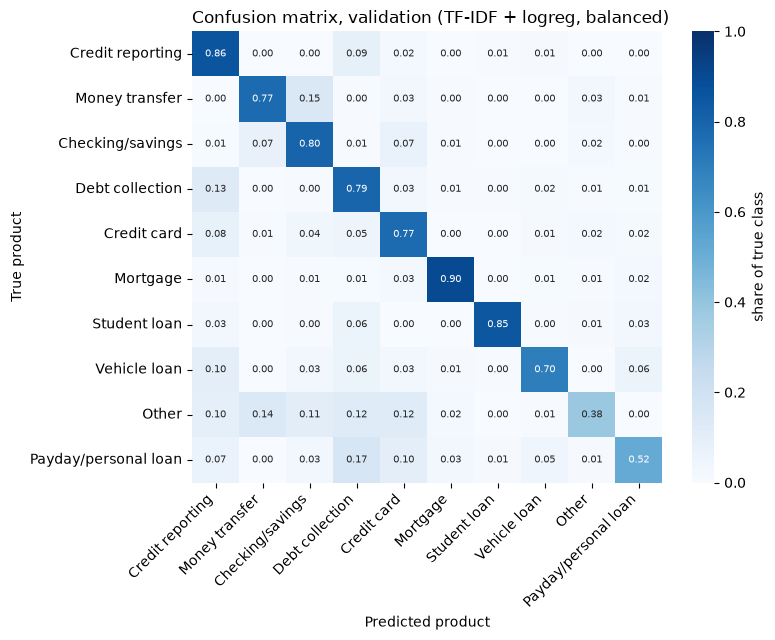

In [10]:
cm = confusion_matrix(y_valid, pred_bal, labels=ORDER, normalize="true")
labels = [SHORT[p] for p in ORDER]

fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1,
            xticklabels=labels, yticklabels=labels, cbar_kws={"label": "share of true class"},
            annot_kws={"fontsize": 7}, ax=ax)
ax.set_xlabel("Predicted product")
ax.set_ylabel("True product")
ax.set_title("Confusion matrix, validation (TF-IDF + logreg, balanced)", loc="left")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig(FIG / "03_confusion_valid.png", dpi=150)
plt.show()

In [11]:
# The biggest confusions as a list: true -> predicted, share of the true class
pairs = (pd.DataFrame(cm, index=labels, columns=labels)
           .stack().rename("share").reset_index()
           .rename(columns={"level_0": "true", "level_1": "predicted"}))
pairs[pairs["true"] != pairs["predicted"]].sort_values("share", ascending=False).head(8).round(3)

,true,predicted,share
93,Payday/personal loan,Debt collection,0.166
12,Money transfer,Checking/savings,0.148
81,Other,Money transfer,0.141
30,Debt collection,Credit reporting,0.127
83,Other,Debt collection,0.124
84,Other,Credit card,0.119
82,Other,Checking/savings,0.107
94,Payday/personal loan,Credit card,0.103


## Save the models

`joblib` saves the whole fitted Pipeline (vocabulary, IDF weights and the logistic regression) in one file. Notebooks 05 and 06 load it instead of refitting.

In [12]:
joblib.dump(lr, MODELS / "tfidf_logreg.joblib")
joblib.dump(lr_bal, MODELS / "tfidf_logreg_balanced.joblib")
pd.DataFrame(results).to_csv(ROOT / "reports" / "03_valid_scores.csv", index=False)
print("saved")

saved
